# 02 · Training

All models are trained with `python -m ml.src.train --config ml/configs/<name>.json` (AdamW, class-weighted cross-entropy, cosine schedule, early stopping on validation macro-F1, seed 42). This notebook loads the recorded histories.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'ml' / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
DATA_DIR = os.environ.get('WASTEWISE_DATA_DIR', str(ROOT / 'ml/datasets/processed'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 160)

In [2]:
cfgs = {p.stem: json.load(open(p)) for p in sorted(Path('ml/configs').glob('*.json'))}
pd.DataFrame(cfgs).T

,experiment_id,arch,pretrained,batch_size,finetune_epochs,lr_finetune,weight_decay,dropout,early_stopping_patience,scheduler,max_minutes,warmup_epochs,lr_head,unfreeze_from
custom_cnn,exp01_custom_cnn,custom_cnn,False,32,18,0.001,0.0005,0.4,5,cosine,45,NaN,NaN,NaN
efficientnet_b0,exp03_efficientnet_b0,efficientnet_b0,True,32,10,0.0003,NaN,NaN,4,NaN,70,3,0.001,5
mobilenet_v3,exp02_mobilenet_v3_large,mobilenet_v3_large,True,32,12,0.0003,NaN,NaN,4,NaN,50,3,0.001,10


In [3]:
hist = {}
for d in sorted(Path('ml/models/experiments').glob('*/training_history.json')):
    hist[d.parent.name] = pd.DataFrame(json.load(open(d))['history'])
list(hist)

['exp01_custom_cnn', 'exp02_mobilenet_v3_large', 'exp03_efficientnet_b0']

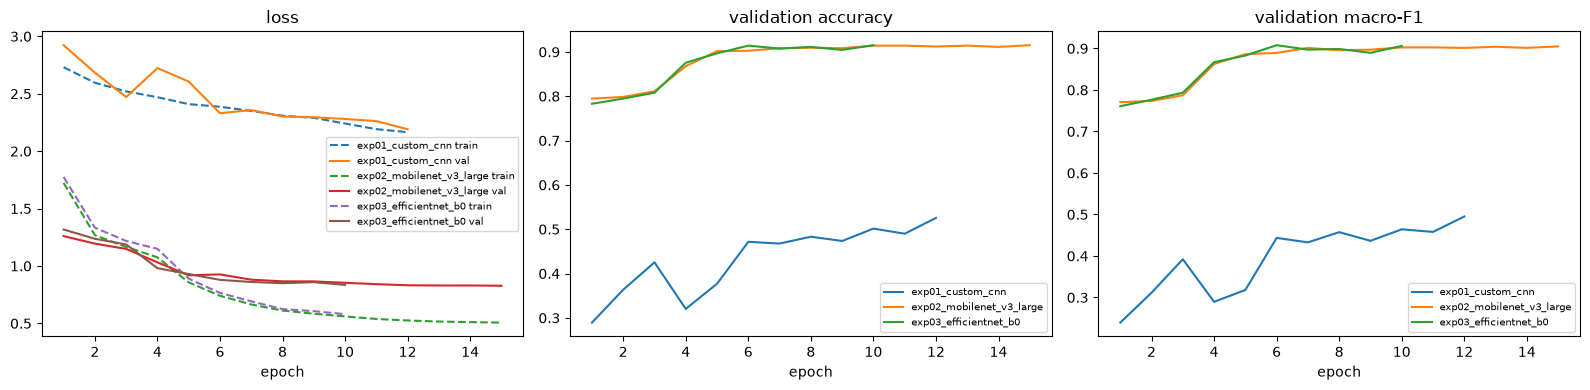

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, h in hist.items():
    axes[0].plot(h['epoch'], h['train_loss'], '--', label=f'{name} train'); axes[0].plot(h['epoch'], h['val_loss'], label=f'{name} val')
    axes[1].plot(h['epoch'], h['val_acc'], label=name); axes[2].plot(h['epoch'], h['val_f1_macro'], label=name)
for ax, t in zip(axes, ['loss', 'validation accuracy', 'validation macro-F1']): ax.set_title(t); ax.set_xlabel('epoch'); ax.legend(fontsize=7)
plt.tight_layout()

In [5]:
summ = {d.parent.name: json.load(open(d)) for d in sorted(Path('ml/models/experiments').glob('*/train_summary.json'))}
pd.json_normalize(list(summ.values())).set_index('experiment_id').drop(columns=['checkpoint'])

,arch,epochs_run,training_minutes,params,device,best.f1_macro,best.acc,best.epoch,best.train_acc
experiment_id,,,,,,,,,
exp01_custom_cnn,custom_cnn,12,46.6,1955674,cpu,0.495064,0.525554,12,0.515208
exp02_mobilenet_v3_large,mobilenet_v3_large,15,47.6,3481426,cpu,0.904866,0.915140,15,0.996458
exp03_efficientnet_b0,efficientnet_b0,10,52.3,4680862,cpu,0.907832,0.914176,6,0.921042
